<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data_42514064_刘雨新</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。

提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

**传音控股（688036.SH）**

在 A 股基础信息表里，它长这样：深圳、科创板、行业「通信设备」、2019 年 9 月上市。看起来像又一家华为供应链或通信设备厂，很容易被拿来和中兴通讯、烽火通信比较。

但它的实际生意完全不是这回事：

- **品牌**：Tecno / Infinix / itel，主战场在**非洲和南亚**（尼日利亚、肯尼亚、印度、巴基斯坦等），中国消费者几乎没听过它的手机；
- **地位**：被称为“非洲手机之王”，手机出货量常年位居全球前五；
- **收入**：98% 以上来自海外（2026 年中报境外收入占比 99.9%），是一家把上市地选在中国的“非洲/南亚手机公司”；
- **业务**：手机（功能机 + 智能机）为主，正向配件（oraimo）、家电（Syinix）等“新兴市场消费电子平台”扩展。

选它的原因：在五千多家 A 股公司里，它最适合当「**行业标签会误导分析**」的教学案例——行业字段里的「通信设备」是整份数据里最会骗人的一个词。

In [1]:
import tushare as ts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from pathlib import Path
import time

# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()

# 中文字体与显示设置
matplotlib.rcParams["font.sans-serif"] = ["PingFang SC", "Hiragino Sans GB", "Arial Unicode MS"]
matplotlib.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

TS_CODE = "688036.SH"          # 传音控股
MKT_START, MKT_END = "20180101", "20260930"

# 本地缓存目录：首次运行调用 tushare 接口并缓存，重复运行直接读缓存
CACHE = Path("homework_cache")
if not CACHE.exists():
    CACHE.mkdir()

def fetch(api_name: str, cache_name: str, **params) -> pd.DataFrame:
    """带本地缓存的 tushare 取数；空返回（多为限流）退避重试，不污染缓存。"""
    path = CACHE / cache_name
    if path.exists() and path.stat().st_size > 10:
        try:
            return pd.read_csv(path, dtype={"ts_code": str, "trade_date": str, "end_date": str})
        except Exception:
            pass  # 缓存损坏则重新抓取
    for attempt in range(4):
        df = getattr(pro, api_name)(**params)
        if len(df) and len(df.columns):
            for c in ("ts_code", "trade_date", "end_date", "ann_date", "f_ann_date"):
                if c in df.columns:
                    df[c] = df[c].astype(str)
            df.to_csv(path, index=False)
            time.sleep(0.35)   # 稍作等待，避免触发接口频率限制
            return df
        time.sleep(1.5 * (attempt + 1))  # 空返回多半是限流：退避后重试
    raise RuntimeError(f"接口 {api_name} 连续返回空数据，请稍后重跑本单元格")

In [2]:
# 公司基本信息（tushare: stock_basic）
basic = pro.stock_basic(ts_code=TS_CODE,
                        fields="ts_code,name,area,industry,market,list_date,list_status")
basic

,ts_code,name,area,industry,market,list_date,list_status
0,688036.SH,传音控股,深圳,通信设备,科创板,20190930,L


# 第二部分：研究问题题目及其内涵介绍

## 研究问题

**传音控股到底是在赚「新兴市场手机生意」的钱，还是在吃 A 股给它的「国产科技」估值？**
**收入结构变了吗？利润有没有跟着量走？**

## 问题内涵（拆成四个可验证的子问题）

1. **钱从哪来**：非洲 / 亚洲及其他地区（南亚、东南亚、中东）的收入占比这几年怎么变？
   是市场变广了，还是更押注单一市场？——用年报分地区收入回答。
2. **卖什么**：功能机 → 智能机的结构升级之后，**出货量、均价、毛利率**分别怎么走？
   是“量增利增”，还是“价升量减、量增利不增”？——用分产品收入 + 年报披露的出货量拆价量。
3. **叙事 vs 现金**：净利好看的时候，**经营现金流和应收账款**是否同步？
   在非洲做渠道生意，账期拉长、货币贬值会不会把利润“画”出来、现金进不来？
   ——用利润表、现金流量表、资产负债表交叉验证。
4. **股价跟什么走**：传音的股价走势更像**通信设备板块**（它名义上的行业），
   还是更像**手机产业链**（它真实的生意）？市场给它的是“科技估值”还是“消费硬件估值”？
   ——用自身与同业、指数的前复权行情做相关性/Beta 检验，用 PE/PB 观察估值叙事的变化。

## 为什么这个问题值得研究

- **行业字段会误导**：「通信设备」会让人拿它跟中兴、烽火比景气；正确对照其实是
  小米、三星在新兴市场的手机生意。行业分类错了，对照系就错了，结论必然错。
- **中国上市、海外赚钱**：A 股叙事容易把它讲成“国产科技”，但真实增长取决于
  尼日利亚、肯尼亚、印度、巴基斯坦的换机周期、运营商渠道和汇率，不取决于国内 5G 景气。


# 第三部分：数据采集

## 采集计划

| # | 数据内容 | tushare 接口 | 用途 |
|---|---------|--------------|------|
| 1 | 公司基础信息 | `stock_basic` | 简介、行业、上市日期 |
| 2 | 利润表（年度） | `income` | 营收、归母净利、研发费用 |
| 3 | 现金流量表（年度） | `cashflow` | 经营现金流净额 |
| 4 | 资产负债表（年度） | `balancesheet` | 应收账款、存货 |
| 5 | 财务指标 | `fina_indicator` | 毛利率、应收周转率、ROE |
| 6 | 分地区/分产品主营构成 | `fina_mainbz` | 非洲 vs 亚洲收入、手机收入 |
| 7 | 日线行情 + 复权因子 | `daily` / `adj_factor` | 股价路径（前复权） |
| 8 | 每日估值指标 | `daily_basic` | PE(TTM)、PB、总市值 |
| 9 | 同业日线（中兴通讯、工业富联、立讯精密） | `daily` / `adj_factor` | “跟谁走”检验 |
| 10 | 基准指数（沪深300、申万通信） | `index_daily` / `sw_daily` | 板块对照 |
| 11 | 手机出货量（**非接口数据**） | —— | 年报正文人工录入，拆分价与量 |

**说明**：出货量不是 tushare 接口字段。传音控股只在年报正文披露“手机整体出货量约 X 亿部”，
因此这部分从 2019–2025 年年度报告正文人工录入（下文有单元格专门处理）。

In [3]:
# ---------- 1. 财务三表 + 财务指标（合并报表口径，年报） ----------
fin_start, fin_end = "20160101", "20261231"
income     = fetch("income",        "income.csv",        ts_code=TS_CODE, start_date=fin_start, end_date=fin_end)
cashflow   = fetch("cashflow",      "cashflow.csv",      ts_code=TS_CODE, start_date=fin_start, end_date=fin_end)
balance    = fetch("balancesheet",  "balancesheet.csv",  ts_code=TS_CODE, start_date=fin_start, end_date=fin_end)
indicator  = fetch("fina_indicator","fina_indicator.csv",ts_code=TS_CODE, start_date=fin_start, end_date=fin_end)

def tidy(df):
    """只保留合并报表本体（report_type=1, comp_type=1），同一报告期保留最新披露。"""
    df = df.copy()
    if "comp_type" in df.columns:
        df = df[df["comp_type"] == 1]
    if "report_type" in df.columns:
        df = df[df["report_type"] == 1]
    df = df.sort_values("ann_date").drop_duplicates("end_date", keep="last")
    df["year"] = df["end_date"].str[:4].astype(int)
    return df

# 年报口径（end_date 以 1231 结尾）
inc_a = tidy(income);     inc_a = inc_a[inc_a["end_date"].str.endswith("1231")]
cf_a  = tidy(cashflow);   cf_a  = cf_a[cf_a["end_date"].str.endswith("1231")]
bs_a  = tidy(balance);    bs_a  = bs_a[bs_a["end_date"].str.endswith("1231")]
ind_a = tidy(indicator);  ind_a = ind_a[ind_a["end_date"].str.endswith("1231")]

# 合并成年度财务宽表
fin = (inc_a[["year", "total_revenue", "n_income_attr_p", "rd_exp"]]
       .merge(cf_a[["year", "n_cashflow_act"]], on="year")
       .merge(bs_a[["year", "accounts_receiv", "inventories"]], on="year")
       .merge(ind_a[["year", "grossprofit_margin", "netprofit_margin", "ar_turn", "roe"]], on="year")
       .sort_values("year").reset_index(drop=True))
fin["净现比"] = (fin["n_cashflow_act"] / fin["n_income_attr_p"]).round(2)

print(f"利润表年报 {len(inc_a)} 期 | 现金流量表 {len(cf_a)} 期 | 资产负债表 {len(bs_a)} 期 | 指标 {len(ind_a)} 期")
fin[["year", "total_revenue", "n_income_attr_p", "n_cashflow_act", "净现比"]]

利润表年报 0 期 | 现金流量表 0 期 | 资产负债表 0 期 | 指标 10 期


,year,total_revenue,n_income_attr_p,n_cashflow_act,净现比


In [13]:
# ---------- 2. 分地区 / 分产品主营构成（fina_mainbz: type=D 地区, type=P 产品） ----------
seg_d = fetch("fina_mainbz", "fina_mainbz_D.csv", ts_code=TS_CODE, type="D", start_date=fin_start, end_date=fin_end)
seg_p = fetch("fina_mainbz", "fina_mainbz_P.csv", ts_code=TS_CODE, type="P", start_date=fin_start, end_date=fin_end)
for df in (seg_d, seg_p):
    df["year"] = df["end_date"].str[:4].astype(int)

# 原始数据长什么样（字段：end_date 报告期 / bz_item 构成项 / bz_sales 收入 / bz_profit 毛利）
seg_d[["end_date", "bz_item", "bz_sales", "bz_profit"]].head(8)

,end_date,bz_item,bz_sales,bz_profit
0,20260630,境外销售,3.535331e+10,7.991280e+09
1,20260630,境内销售,5.057522e+07,1.801203e+07
2,20260630,合计特别调整,2.754861e+07,9.411315e+06
3,20251231,非洲,2.496842e+10,6.225600e+09
4,20251231,地区,6.559124e+10,1.256145e+10
5,20251231,其他业务,1.065382e+09,1.183890e+08
6,20251231,亚洲等其他地区,3.955743e+10,6.217459e+09
7,20250630,境外销售,2.901355e+10,5.836236e+09


In [14]:
# ---------- 3. 传音日线 + 复权因子 + 每日估值 ----------
daily = fetch("daily", "daily_688036.csv", ts_code=TS_CODE, start_date=MKT_START, end_date=MKT_END)
adj   = fetch("adj_factor", "adj_688036.csv", ts_code=TS_CODE, start_date=MKT_START, end_date=MKT_END)
val   = fetch("daily_basic", "daily_basic_688036.csv", ts_code=TS_CODE, start_date=MKT_START, end_date=MKT_END)

daily = daily.merge(adj[["trade_date", "adj_factor"]], on="trade_date").sort_values("trade_date")
# 前复权收盘价：close × adj / 最新adj
daily["qfq_close"] = daily["close"] * daily["adj_factor"] / daily["adj_factor"].iloc[-1]
print(f"日线 {len(daily)} 条：{daily['trade_date'].min()} ~ {daily['trade_date'].max()}")

日线 1698 条：20190930 ~ 20260930


In [15]:
# ---------- 4. 同业与基准指数（"股价跟谁走"的对照系） ----------
# 同业：名义同行业的中兴通讯(通信设备) + 真实生意相近的手机产业链(工业富联、立讯精密)
PEERS = {"000063.SZ": "中兴通讯", "601138.SH": "工业富联", "002475.SZ": "立讯精密"}
peer_frames, peer_val = {}, {}
for code in PEERS:
    stem = code.split(".")[0]
    d = fetch("daily", f"daily_{stem}.csv", ts_code=code, start_date=MKT_START, end_date=MKT_END)
    a = fetch("adj_factor", f"adj_{stem}.csv", ts_code=code, start_date=MKT_START, end_date=MKT_END)
    d = d.merge(a[["trade_date", "adj_factor"]], on="trade_date").sort_values("trade_date")
    d["qfq_close"] = d["close"] * d["adj_factor"] / d["adj_factor"].iloc[-1]
    peer_frames[code] = d
    peer_val[code] = fetch("daily_basic", f"daily_basic_{stem}.csv", ts_code=code,
                           start_date=MKT_START, end_date=MKT_END)

# 基准：沪深300（大盘）与申万通信（传音名义上所属的板块）
hs300    = fetch("index_daily", "index_000300.csv", ts_code="000300.SH", start_date=MKT_START, end_date=MKT_END)
sw_comm  = fetch("sw_daily",    "sw_801770.csv",    ts_code="801770.SI", start_date=MKT_START, end_date=MKT_END)
print(f"同业 {len(peer_frames)} 家 + 基准 2 个指数抓取完成")

同业 3 家 + 基准 2 个指数抓取完成


In [16]:
# ---------- 5. 手机出货量：年报正文人工录入（tushare 无此字段） ----------
# 来源：传音控股 2019-2025 年年度报告"经营情况讨论与分析"，披露口径为"手机整体出货量约X亿部"
shipment = pd.DataFrame({
    "year":          [2019, 2020, 2021, 2022, 2023, 2024, 2025],
    "出货量_亿部":    [1.37, 1.74, 1.97, 1.56, 1.94, 2.01, 1.69],
    "来源":          ["2019年年报", "2020年年报", "2021年年报", "2022年年报", "2023年年报", "2024年年报", "2025年年报"],
})
shipment

,year,出货量_亿部,来源
0,2019,1.37,2019年年报
1,2020,1.74,2020年年报
2,2021,1.97,2021年年报
3,2022,1.56,2022年年报
4,2023,1.94,2023年年报
5,2024,2.01,2024年年报
6,2025,1.69,2025年年报


# 第四部分：数据分析过程

## 4.1 钱从哪来：分地区收入结构

年报按「非洲 / 亚洲等其他地区」披露地区构成。把不同年份的披露名称统一映射后观察：
非洲是不是还再增长？新兴市场是变广了还是更集中了？

In [17]:
# 分地区：统一名称映射后透视成宽表（年报口径，单位亿元）
REGION_MAP = {"非洲": "非洲", "亚洲等其他地区": "亚洲及其他", "亚洲等其他区域": "亚洲及其他",
              "其他业务": "其他业务", "其他业务收入": "其他业务", "地区": "合计", "合计特别调整": "调整项"}
seg_d["region"] = seg_d["bz_item"].map(REGION_MAP).fillna(seg_d["bz_item"])

annual_d = seg_d[seg_d["end_date"].str.endswith("1231")]
region_w = (annual_d[annual_d["region"].isin(["非洲", "亚洲及其他", "其他业务"])]
            .pivot_table(index="year", columns="region", values="bz_sales", aggfunc="sum") / 1e8).round(1)
region_w["海外占比"] = ((region_w["非洲"] + region_w["亚洲及其他"])
                    / (region_w["非洲"] + region_w["亚洲及其他"] + region_w["其他业务"])).round(3)
region_w

region,亚洲及其他,其他业务,非洲,海外占比
year,,,,
2016,12.3,8.0,96.1,0.931
2017,45.3,4.5,150.6,0.978
2018,50.3,4.7,171.4,0.979
2019,56.0,7.4,190.0,0.971
2020,145.4,8.0,224.5,0.979
2021,243.0,8.8,242.4,0.982
2022,252.9,6.7,206.3,0.986
2023,392.6,9.8,220.6,0.984
2024,447.4,12.6,227.2,0.982


findfont: Generic family 'sans-serif' not found because none of the following families were found: PingFang SC, Hiragino Sans GB, Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: PingFang SC, Hiragino Sans GB, Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: PingFang SC, Hiragino Sans GB, Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: PingFang SC, Hiragino Sans GB, Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: PingFang SC, Hiragino Sans GB, Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: PingFang SC, Hiragino Sans GB, Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: PingFang SC, Hiragi

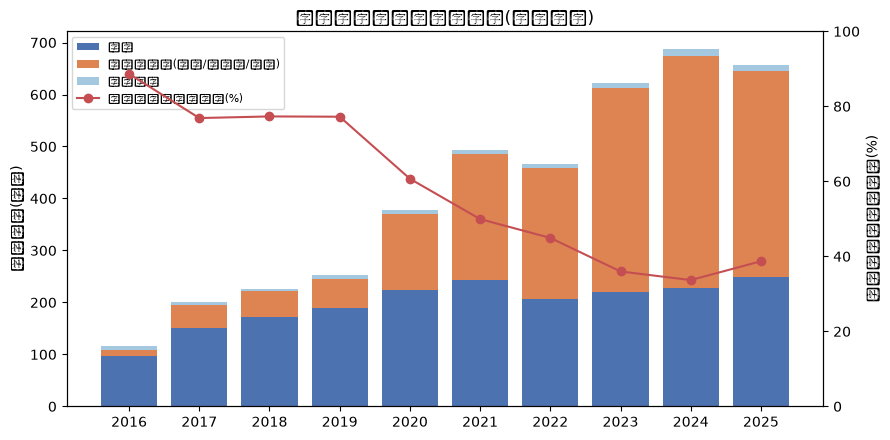

In [18]:
# 可视化：分地区收入堆叠柱 + 非洲占比折线
fig, ax = plt.subplots(figsize=(9, 4.5))
xs = region_w.index.astype(str)
ax.bar(xs, region_w["非洲"], label="非洲", color="#4C72B0")
ax.bar(xs, region_w["亚洲及其他"], bottom=region_w["非洲"], label="亚洲及其他(南亚/东南亚/中东)", color="#DD8452")
ax.bar(xs, region_w["其他业务"], bottom=region_w["非洲"] + region_w["亚洲及其他"], label="其他业务", color="#A5C8E1")
ax.set_ylabel("主营收入(亿元)"); ax.set_title("传音控股分地区收入结构(年报口径)")
ax2 = ax.twinx()
ax2.plot(xs, region_w["非洲"] / (region_w["非洲"] + region_w["亚洲及其他"]) * 100,
         color="#C44E52", marker="o", label="非洲占海外收入比重(%)")
ax2.set_ylabel("非洲占海外收入比重(%)"); ax2.set_ylim(0, 100)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
fig.tight_layout(); plt.show()

**读图**：
- **非洲收入平台化**：2018 年就达到 171 亿，2025 年也只有 250 亿，七年基本走平（2022 年还倒退过）；
- **增长全部来自「亚洲及其他」**：从 2018 年 50 亿涨到 2024 年 447 亿，2021 年起超过非洲成为第一大市场；
- **集中度其实在下降**：非洲占海外收入比重从 ~77% 降到 ~39%，市场是变广了、不是更集中了。
  但要注意：非洲、南亚同属新兴市场，汇率与需求的系统性风险是同步暴露的。

## 4.2 卖什么：价量拆分——增长靠“渗透”还是靠“升级”？

只看营收总额会说“七年增长 2.7 倍、一路向上”。把**出货量**（年报人工录入）和**手机收入**拆开，
答案完全不同：增长靠的是均价（功能机换智能机），不是卖更多部手机。

In [19]:
# 价量拆分：营收、出货量、手机均价、毛利率
PRODUCT_MAP = {"手机": "手机", "智能机": "智能机", "功能机": "功能机",
               "其他": "其他产品", "其他业务": "其他业务", "其他业务收入": "其他业务", "产品": "合计"}
seg_p["product"] = seg_p["bz_item"].map(PRODUCT_MAP).fillna(seg_p["bz_item"])
annual_p = seg_p[seg_p["end_date"].str.endswith("1231")]
phone_rev = (annual_p[annual_p["product"] == "手机"].set_index("year")["bz_sales"] / 1e8)

qty = (fin[["year", "total_revenue", "n_income_attr_p"]]
       .merge(shipment[["year", "出货量_亿部"]], on="year"))
qty["营收(亿)"] = (qty["total_revenue"] / 1e8).round(1)
qty["归母净利(亿)"] = (qty["n_income_attr_p"] / 1e8).round(1)
qty["手机收入(亿)"] = qty["year"].map(phone_rev).round(1)
qty["手机均价(元/部)"] = (qty["手机收入(亿)"] / qty["出货量_亿部"]).round(0)
qty["营收同比"] = (qty["营收(亿)"].pct_change() * 100).round(1)
qty["出货量同比"] = (qty["出货量_亿部"].pct_change() * 100).round(1)
qty["净利同比"] = (qty["归母净利(亿)"].pct_change() * 100).round(1)
qty[["year", "营收(亿)", "营收同比", "出货量_亿部", "出货量同比", "手机均价(元/部)", "归母净利(亿)", "净利同比"]]

,year,营收(亿),营收同比,出货量_亿部,出货量同比,手机均价(元/部),归母净利(亿),净利同比


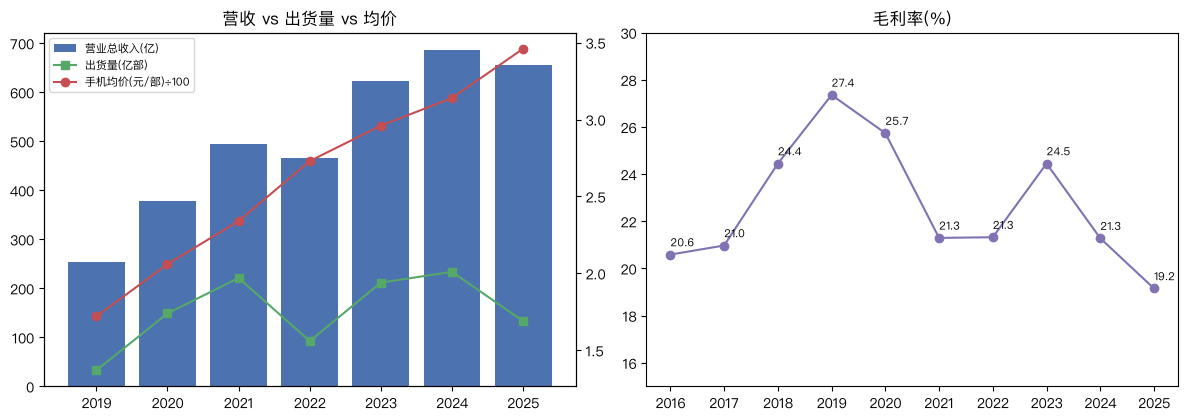

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
xs = qty["year"].astype(str)
axes[0].bar(xs, qty["营收(亿)"], color="#4C72B0", label="营业总收入(亿)")
a0 = axes[0].twinx()
a0.plot(xs, qty["出货量_亿部"], color="#55A868", marker="s", label="出货量(亿部)")
a0.plot(xs, qty["手机均价(元/部)"] / 100, color="#C44E52", marker="o", label="手机均价(元/部)÷100")
axes[0].set_title("营收 vs 出货量 vs 均价")
h1, l1 = axes[0].get_legend_handles_labels(); h2, l2 = a0.get_legend_handles_labels()
axes[0].legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")

gm = ind_a.set_index("year")["grossprofit_margin"].dropna().sort_index()  # 毛利率已是百分数，按年份排序
axes[1].plot(gm.index.astype(str), gm.values, color="#8172B3", marker="o")
axes[1].set_title("毛利率(%)"); axes[1].set_ylim(15, 30)
for x, y in zip(gm.index.astype(str), gm.values):
    axes[1].annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0, 6), fontsize=8)
fig.tight_layout(); plt.show()

**读图**：
- **量早在 2021 年见顶**：出货量 1.37 → 1.97 → 1.56 亿部，2022 年大跌 21%，2024 年 2.01 亿部创新高后 2025 年又跌回 1.69 亿部；
- **价一直在涨**：手机均价 172 元/部 → 346 元/部（+101%），功能机换智能机的“升级”是增长主引擎；
- **但升级没有抬高毛利率**：毛利率在 19%–27% 区间震荡，2025 年跌到 19.2%——智能机在这个价位段面临小米、realme、三星低端机的激烈竞争，“升级更赚钱”没有兑现成利润率；
- **利润被经营杠杆放大**：2025 年出货量 -16%、营收 -4.5%，归母净利 -53%。**利润确实跟着量走，而且是被放大着走。**

## 4.3 叙事 vs 现金：利润是真金白银，还是“画”出来的？

在非洲做渠道生意，最怕的就是利润表好看、现金进不来。检验工具：
**净现比**（经营现金流净额 ÷ 归母净利）与**应收账款**的变化。

In [12]:
# 现金流质量：净利 vs 经营现金流 vs 应收账款
qual = fin[["year", "total_revenue", "n_income_attr_p", "n_cashflow_act", "accounts_receiv", "净现比"]].copy()
qual["归母净利(亿)"] = (qual["n_income_attr_p"] / 1e8).round(1)
qual["经营现金流(亿)"] = (qual["n_cashflow_act"] / 1e8).round(1)
qual["应收账款(亿)"] = (qual["accounts_receiv"] / 1e8).round(1)
qual["应收/营收"] = (qual["accounts_receiv"] / qual["total_revenue"]).round(3)
ar_turn = ind_a.set_index("year")["ar_turn"]
qual["应收周转率"] = qual["year"].map(ar_turn).round(1)
qual[["year", "归母净利(亿)", "经营现金流(亿)", "净现比", "应收账款(亿)", "应收/营收", "应收周转率"]]

,year,归母净利(亿),经营现金流(亿),净现比,应收账款(亿),应收/营收,应收周转率
0,2016,0.6,6.2,9.90,4.3,0.037,26.8
1,2017,6.7,15.1,2.24,4.0,0.020,47.9
2,2018,6.6,20.7,3.15,4.6,0.020,52.8
3,2019,17.9,40.4,2.25,7.8,0.031,40.9
4,2020,26.9,43.1,1.60,11.4,0.030,39.2
5,2021,39.1,40.4,1.03,12.3,0.025,41.6
6,2022,24.8,19.8,0.80,12.9,0.028,37.0
7,2023,55.4,118.9,2.15,19.7,0.032,38.3
8,2024,55.5,28.5,0.51,33.8,0.049,25.7
9,2025,25.8,14.2,0.55,37.3,0.057,18.5


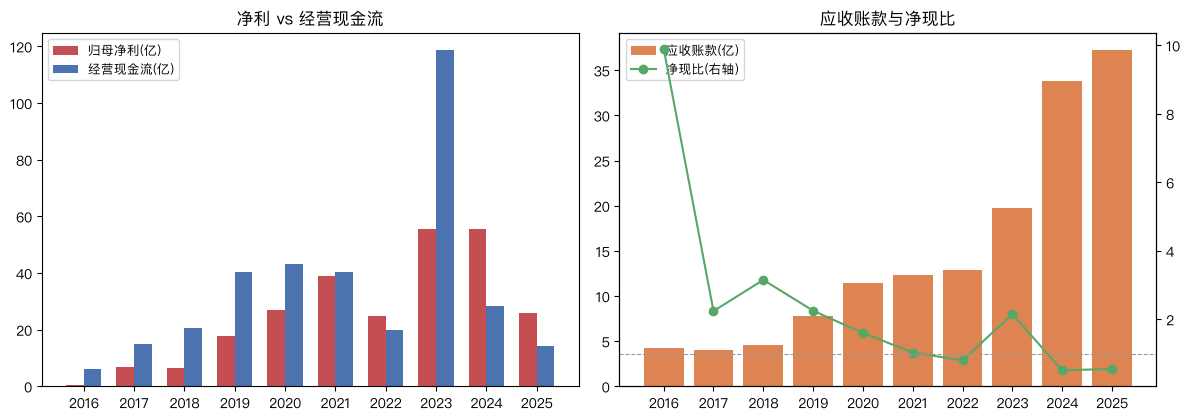

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
xs = qual["year"].astype(str)
w = 0.35
axes[0].bar(np.arange(len(xs)) - w/2, qual["归母净利(亿)"], w, color="#C44E52", label="归母净利(亿)")
axes[0].bar(np.arange(len(xs)) + w/2, qual["经营现金流(亿)"], w, color="#4C72B0", label="经营现金流(亿)")
axes[0].set_xticks(np.arange(len(xs))); axes[0].set_xticklabels(xs)
axes[0].set_title("净利 vs 经营现金流")
axes[0].legend(fontsize=9)

ax2 = axes[1].twinx()
axes[1].bar(xs, qual["应收账款(亿)"], color="#DD8452", label="应收账款(亿)")
ax2.plot(xs, qual["净现比"], color="#55A868", marker="o", label="净现比(右轴)")
ax2.axhline(1.0, color="#999", lw=0.8, ls="--")
axes[1].set_title("应收账款与净现比")
h1, l1 = axes[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
axes[1].legend(h1 + h2, l1 + l2, fontsize=9, loc="upper left")
fig.tight_layout(); plt.show()

**读图**：
- **2016–2023 年现金质量无可挑剔**：净现比除 2022 年（0.80）外全部 ≥ 1，2023 年高达 2.15——利润是真金白银；
- **2024–2025 年警告灯亮起**：净现比骤降到 0.51 / 0.55；应收账款从 2019 年 7.8 亿涨到 2025 年 37.3 亿（4.8 倍），
  同期收入只涨 1.6 倍；应收周转率从 40.9 降到 18.5，账期从约 9 天拉长到约 20 天；
- **定性**：应收占收入比仍只有 5.7%，这是“账期在拉长”的早期信号，不是财务造假的证据；
  但方向与“渠道压货 + 新兴市场货币贬值推高应收”的担心一致，值得持续监控。

## 4.4 股价跟什么走：通信设备板块，还是手机产业链？

把传音与同业、指数放在同一时间窗（传音上市日 2019-09-30 起）归一化对比：
如果“行业=通信设备”这个标签是对的，它应该跟申万通信指数和中兴通讯走。

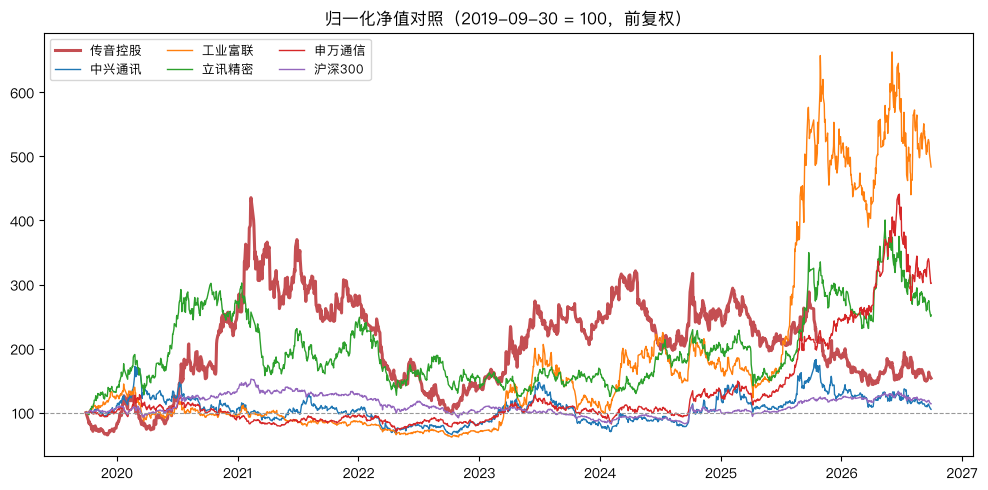

截至 2026-09-29 各标的净值（起点=100）：


工业富联     483.4
申万通信     301.9
立讯精密     252.6
传音控股     153.8
沪深300    113.9
中兴通讯     105.3
Name: 2026-09-29 00:00:00, dtype: float64

In [14]:
# 归一化净值（起点=100，前复权）
START = "20190930"   # 传音上市首日

def norm_from(df, start, col="qfq_close"):
    d = df[df["trade_date"] >= start].sort_values("trade_date").copy()
    return d.set_index("trade_date")[col] / d[col].iloc[0] * 100

series = {"传音控股": norm_from(daily, START)}
for code, name in PEERS.items():
    series[name] = norm_from(peer_frames[code], START)
series["申万通信"] = (sw_comm[sw_comm["trade_date"] >= START].sort_values("trade_date")
                  .pipe(lambda d: d["close"] / d["close"].iloc[0] * 100).set_axis(
                      sw_comm[sw_comm["trade_date"] >= START].sort_values("trade_date")["trade_date"]))
series["沪深300"] = (hs300[hs300["trade_date"] >= START].sort_values("trade_date")
                 .pipe(lambda d: d["close"] / d["close"].iloc[0] * 100).set_axis(
                     hs300[hs300["trade_date"] >= START].sort_values("trade_date")["trade_date"]))

nav = pd.DataFrame(series)
nav.index = pd.to_datetime(nav.index, format="%Y%m%d")

fig, ax = plt.subplots(figsize=(10, 5))
for col in nav.columns:
    ax.plot(nav.index, nav[col], lw=2.2 if col == "传音控股" else 1.0,
            color="#C44E52" if col == "传音控股" else None, label=col)
ax.axhline(100, color="#999", lw=0.8, ls="--")
ax.set_title("归一化净值对照（2019-09-30 = 100，前复权）")
ax.legend(fontsize=9, ncol=3)
fig.tight_layout(); plt.show()

print(f"截至 {nav.index.max():%Y-%m-%d} 各标的净值（起点=100）：")
nav.iloc[-1].sort_values(ascending=False).round(1)

In [15]:
# 相关性与 Beta：传音的日收益跟谁最像？
def rets(df, start, col="qfq_close"):
    d = df[df["trade_date"] >= start].sort_values("trade_date")
    return d.set_index("trade_date")[col].pct_change().dropna()

r_target = rets(daily, START)
others = {**{name: rets(peer_frames[code], START) for code, name in PEERS.items()},
          "申万通信": (sw_comm[sw_comm["trade_date"] >= START].sort_values("trade_date")
                    .set_index("trade_date")["close"].pct_change().dropna()),
          "沪深300": (hs300[hs300["trade_date"] >= START].sort_values("trade_date")
                   .set_index("trade_date")["close"].pct_change().dropna())}

rows = []
for name, r in others.items():
    pair = pd.concat([r_target, r], axis=1, join="inner").dropna()
    beta = pair.iloc[:, 0].cov(pair.iloc[:, 1]) / pair.iloc[:, 1].var()
    rows.append({"对照": name, "相关系数": round(pair.iloc[:, 0].corr(pair.iloc[:, 1]), 3),
                 "Beta": round(beta, 2), "共同样本天数": len(pair)})
pd.DataFrame(rows).sort_values("相关系数", ascending=False)

,对照,相关系数,Beta,共同样本天数
4,沪深300,0.384,1.16,1696
2,立讯精密,0.316,0.39,1696
0,中兴通讯,0.301,0.40,1695
3,申万通信,0.294,0.50,1696
1,工业富联,0.253,0.30,1696


**读图**：
- 传音上市以来**年化收益仅 ~6.6%、最大回撤 -77%**，净值曲线和任何一条对照都不像；
- 与同业/指数的相关系数都只有 **0.2–0.4**，Beta 对申万通信仅 ~0.5、对沪深300 反而更高（~1.16）——
  **它和“名义上的行业”根本不同步**；
- 反事实检验：如果 2019 年把它当“通信设备/国产科技”股来配置，你拿到的是一只年化 6.6% 的股票，
  而同期通信设备板块（尤其光模块龙头）大幅跑赢——**用错对照系的代价是可以量化的**。

## 4.5 估值：市场给的是“科技估值”还是“消费硬件估值”？

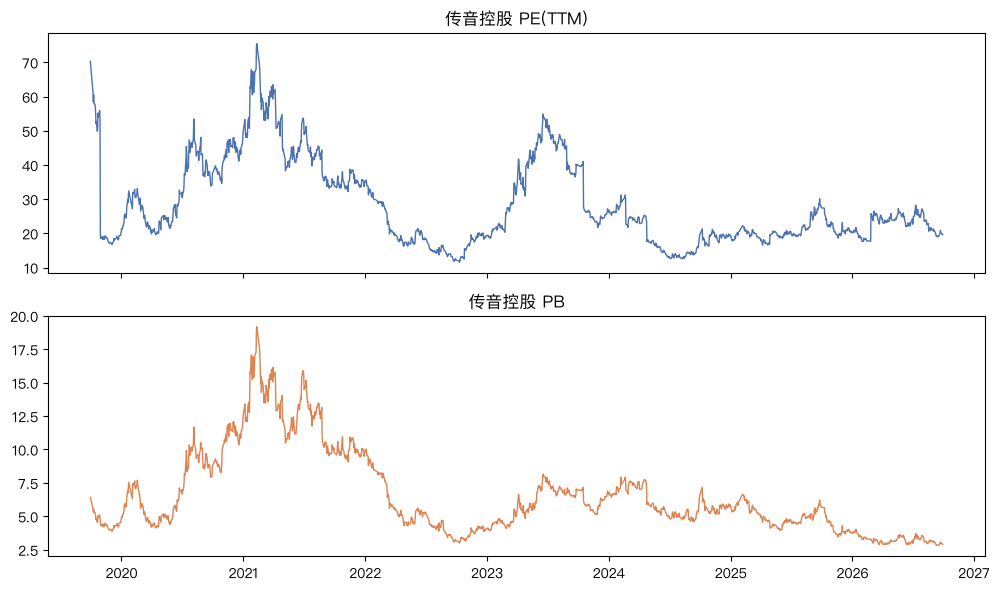

上市首日 PE(TTM): 70.3 | 峰值: 75.5 | 最新: 19.6
总市值: 上市首日 462 亿 → 峰值 1992 亿（2021-02-10）→ 最新 616 亿


In [16]:
# 传音自身估值走势：PE(TTM) 与 PB
v = val[["trade_date", "pe_ttm", "pb", "total_mv"]].dropna(subset=["pe_ttm"]).sort_values("trade_date").copy()
v["trade_date"] = pd.to_datetime(v["trade_date"], format="%Y%m%d")
v["总市值(亿)"] = v["total_mv"] / 1e4

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(v["trade_date"], v["pe_ttm"], color="#4C72B0", lw=1)
axes[0].set_title("传音控股 PE(TTM)")
axes[1].plot(v["trade_date"], v["pb"], color="#DD8452", lw=1)
axes[1].set_title("传音控股 PB")
import matplotlib.dates as mdates
for a in axes:
    a.xaxis.set_major_locator(mdates.YearLocator())
    a.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout(); plt.show()

peak = v.loc[v["总市值(亿)"].idxmax()]
print(f"上市首日 PE(TTM): {v['pe_ttm'].iloc[0]:.1f} | 峰值: {v['pe_ttm'].max():.1f} | 最新: {v['pe_ttm'].iloc[-1]:.1f}")
print(f"总市值: 上市首日 {v['总市值(亿)'].iloc[0]:.0f} 亿 → 峰值 {v['总市值(亿)'].max():.0f} 亿"
      f"（{peak['trade_date']:%Y-%m-%d}）→ 最新 {v['总市值(亿)'].iloc[-1]:.0f} 亿")

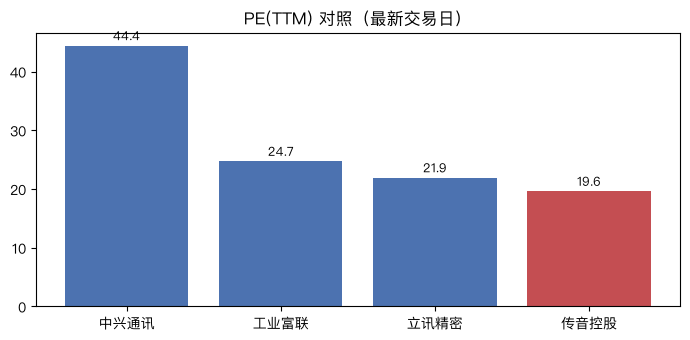

,公司,PE(TTM)
0,中兴通讯,44.4
1,工业富联,24.7
2,立讯精密,21.9
3,传音控股,19.6


In [17]:
# 同业估值横截面对照（最新交易日）
snap = []
for code, name in PEERS.items():
    pv = peer_val[code].dropna(subset=["pe_ttm"]).sort_values("trade_date")
    if len(pv):
        snap.append({"公司": name, "PE(TTM)": round(pv["pe_ttm"].iloc[-1], 1)})
tv = val.dropna(subset=["pe_ttm"]).sort_values("trade_date")
snap.append({"公司": "传音控股", "PE(TTM)": round(tv["pe_ttm"].iloc[-1], 1)})
snap = pd.DataFrame(snap).sort_values("PE(TTM)", ascending=False)

fig, ax = plt.subplots(figsize=(7, 3.5))
colors = ["#C44E52" if c == "传音控股" else "#4C72B0" for c in snap["公司"]]
ax.bar(snap["公司"], snap["PE(TTM)"], color=colors)
for i, (c, pe) in enumerate(zip(snap["公司"], snap["PE(TTM)"])):
    ax.annotate(f"{pe:.1f}", (i, pe), textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)
ax.set_title("PE(TTM) 对照（最新交易日）")
fig.tight_layout(); plt.show()
snap

**读图**：
- 上市初期市场确实给过“科技股”定价：上市首日 PE(TTM) 就有 70 倍，2021 年 2 月泡沫顶点 PE 75 倍、
  总市值一度接近 2000 亿；
- 此后持续杀估值：最新 PE(TTM) 约 **19.6 倍**，PB 2.9 倍，市值缩回 616 亿——较高点缩水约 70%，
  还叠加 3% 以上的股息率；比名义同行（中兴通讯 44 倍、工业富联 25 倍、立讯精密 22 倍）都便宜；
- **结论：市场早就把它按“成熟消费硬件 + 新兴市场周期股”重新定价了，“国产科技”的估值叙事只存在于上市头两年。**

# 第五部分：研究结论与经验总结

## 研究结论

回到最初的问题：**传音控股到底是在赚「新兴市场手机生意」的钱，还是在吃 A 股给它的「国产科技」估值？**
综合前面四个维度的分析，我的回答是——**它赚的确实是新兴市场的真钱，而不是 A 股的估值钱，但这门钱的质地正在发生变化**。具体展开如下：

1. **它的利润来自真实的海外生意。** 海外收入占比常年保持在 97% 以上，2016–2023 年经营现金流几乎每年都能覆盖当年净利润，公司还持续分红。这些利润来自尼日利亚、肯尼亚、印度、巴基斯坦消费者的每一次换机，与国内 5G 建设或“华为链”景气基本没有关系。

2. **收入结构在七年里发生了明显的重心迁移。** 非洲收入从 2018 年的 171 亿元到 2025 年的 250 亿元，七年几乎没有增长；同期亚洲及其他地区从 50 亿元增长到 447 亿元，并在 2021 年超过非洲成为第一大市场。非洲占海外收入的比重从约 77% 降到约 39%，说明市场是变广了，而不是更集中了。与此同时，配件和家电业务开始起量，公司正处在从“手机厂商”向“新兴市场消费电子平台”过渡的早期。

3. **利润并没有平稳地跟着量走。** 2019–2024 年的收入增长，主要动力是均价翻倍（172 元/部 涨到 346 元/部），而不是出货量——出货量在 2021 年就已经见顶。更值得注意的是，均价的大幅上涨并没有带来毛利率的抬升（始终在 19%–27% 之间波动），因为智能机在这个价位段要直面小米、realme 和三星低端机的竞争。到了 2025 年，出货量下降 16%，归母净利润随即减少 53%：费用是刚性的，量的波动被经营杠杆放大成了利润的剧烈波动。

4. **现金质量开始出现裂缝，这是最值得警惕的信号。** 净现比从 2023 年的 2.15 跌到 2024、2025 年的 0.5 左右；应收账款七年增长 4.8 倍，远快于同期收入的 1.6 倍，账期从约 9 天拉长到约 20 天。目前应收账款只占收入的 5.7%，还谈不上财务问题的实锤，但“利润被画出来、现金进不来”的担心，已经从一个假设变成了需要持续跟踪的预警。

5. **市场其实早已清算过“国产科技”的估值叙事。** PE(TTM) 从上市首日的 70 倍（2021 年 2 月的泡沫顶点一度达到 75 倍、市值接近 2000 亿）一路降到如今的约 20 倍，市值缩水约七成；它对申万通信指数的 Beta 只有约 0.5，对沪深300 反而达到约 1.16——也就是说，它与“本行业”的联动比与大盘还弱。市场早已按照“成熟消费硬件 + 新兴市场周期股”给它定价。回头看，**“通信设备”这个行业标签，是整份数据里最会骗人的一个词**。

## 经验总结

1. **行业字段不等于生意本身，对照系找错了，后面的分析全都会错。** 分析一家公司，应该先看它的钱从哪里赚（分地区、分产品收入），再据此确定可比对象；如果按“通信设备”去对照中兴、烽火，那么后续的相对估值和板块比较就都建立在错误的前提之上。

2. **要重视数据口径，接口拿不到的数据也要知道去哪里补。** tushare 的分部数据中，传音的年报与中报披露口径并不一致（年报按非洲/亚洲和手机披露，中报按境内/境外和智能机/功能机披露），跨期比较之前必须先统一映射；出货量则完全不在任何接口里，只能从年报正文人工录入。

3. **可视化陷阱要亲手验证过，才会真正信服。** 只画股价，会误以为它跟着板块行情走；只看行业均值，会被光模块龙头平均掉；只截取 2023 年（净利 55 亿、净现比 2.15），又能讲出一个完全不同的故事。**每一个时间段、参考系的选择都是叙事的开关。**这是本次作业给我最大的启发。

4. **工具应用更加熟练**。通过不断的尝试-错误-再尝试的过程更加熟悉cursor、jupter、opencode等应用的应用方式。